In [3]:
from data import load_credit, clean, split_data
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from ucimlrepo import fetch_ucirepo
from sklearn.datasets import make_moons, make_blobs
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
import logging
from dataclasses import dataclass, field
from pathlib import Path
from __future__ import annotations
logger = logging.getLogger(__name__)

CAT = ["MARRIAGE","EDUCATION", "SEX"]


RANDOM_STATE = 42

In [4]:
df = clean(load_credit())
X_train, X_test, y_train, y_test = split_data(df)
eda = X_train.join(y_train) 
print(X_train.shape, X_test.shape)         
print(eda.shape)
print(eda["default"].value_counts(normalize=True).round(3))
eda.describe().T[["mean", "std", "min", "50%", "max"]].round(1)

(24000, 23) (6000, 23)
(24000, 24)
default
0    0.779
1    0.221
Name: proportion, dtype: float64


,mean,std,min,50%,max
LIMIT_BAL,167364.7,129511.3,10000.0,140000.0,1000000.0
SEX,1.6,0.5,1.0,2.0,2.0
EDUCATION,1.8,0.7,1.0,2.0,4.0
MARRIAGE,1.6,0.5,1.0,2.0,3.0
AGE,35.4,9.2,21.0,34.0,75.0
PAY_1,-0.0,1.1,-2.0,0.0,8.0
PAY_2,-0.1,1.2,-2.0,0.0,8.0
PAY_3,-0.2,1.2,-2.0,0.0,8.0
PAY_4,-0.2,1.2,-2.0,0.0,8.0
PAY_5,-0.3,1.1,-2.0,0.0,8.0


In [5]:
for c in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(eda.groupby(c)["default"].agg(["size", "mean"]).round(3), "\n")

      size   mean
SEX              
1     9486  0.244
2    14514  0.206 

            size   mean
EDUCATION              
1           8455  0.193
2          11256  0.238
3           3903  0.250
4            386  0.073 

           size   mean
MARRIAGE              
1         10892  0.233
2         12806  0.210
3           302  0.255 



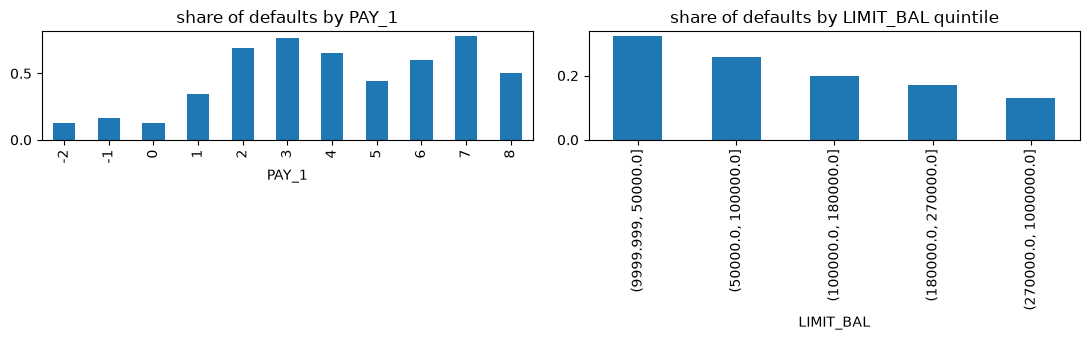

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
eda.groupby("PAY_1")["default"].mean().plot.bar(ax=ax[0], title="share of defaults by PAY_1")
eda.groupby(pd.qcut(eda["LIMIT_BAL"], 5))["default"].mean().plot.bar(ax=ax[1], title="share of defaults by LIMIT_BAL quintile")
plt.tight_layout(); plt.show()

LIMIT_BAL     1.0
AGE           0.7
BILL_AMT1     2.7
BILL_AMT2     2.7
BILL_AMT3     2.7
BILL_AMT4     2.8
BILL_AMT5     2.9
BILL_AMT6     2.9
PAY_AMT1     15.3
PAY_AMT2     21.1
PAY_AMT3     18.6
PAY_AMT4     12.4
PAY_AMT5     11.1
PAY_AMT6     10.5
dtype: float64


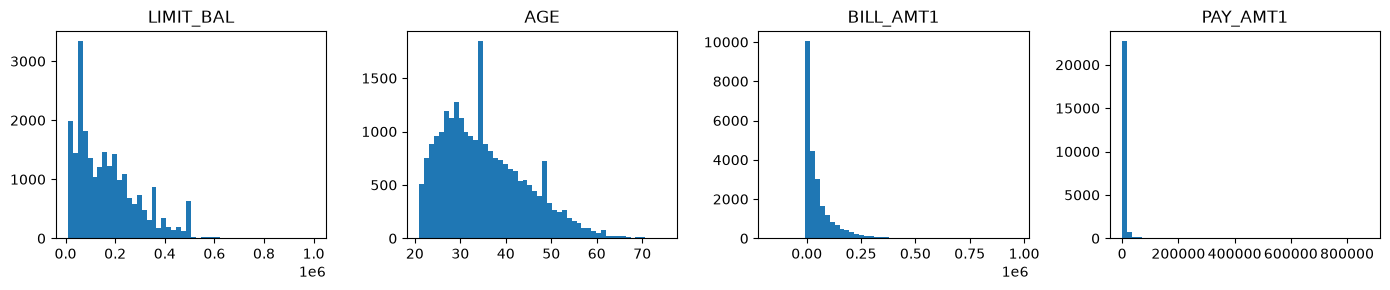

In [7]:
BILLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYS = [f"PAY_AMT{i}" for i in range(1, 7)]

print(eda[["LIMIT_BAL", "AGE"] + BILLS + PAYS].skew().round(1))

fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, c in zip(ax, ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]):
    a.hist(eda[c], bins=50); a.set_title(c)
plt.tight_layout(); plt.show()

In [8]:
print((eda[BILLS] < 0).sum().to_dict())
print((eda[PAYS] == 0).mean().round(2).to_dict())

{'BILL_AMT1': 468, 'BILL_AMT2': 522, 'BILL_AMT3': 515, 'BILL_AMT4': 530, 'BILL_AMT5': 524, 'BILL_AMT6': 556}
{'PAY_AMT1': 0.17, 'PAY_AMT2': 0.18, 'PAY_AMT3': 0.2, 'PAY_AMT4': 0.21, 'PAY_AMT5': 0.22, 'PAY_AMT6': 0.24}


In [9]:
corr = eda.corr()["default"].drop("default").sort_values()
corr.round(3)

LIMIT_BAL   -0.161
PAY_AMT1    -0.073
PAY_AMT2    -0.065
PAY_AMT4    -0.055
PAY_AMT3    -0.054
PAY_AMT6    -0.053
PAY_AMT5    -0.053
SEX         -0.044
MARRIAGE    -0.023
BILL_AMT1   -0.023
BILL_AMT3   -0.018
BILL_AMT2   -0.018
BILL_AMT4   -0.014
BILL_AMT5   -0.010
BILL_AMT6   -0.008
AGE          0.013
EDUCATION    0.032
PAY_6        0.189
PAY_5        0.203
PAY_4        0.220
PAY_3        0.239
PAY_2        0.266
PAY_1        0.328
Name: default, dtype: float64

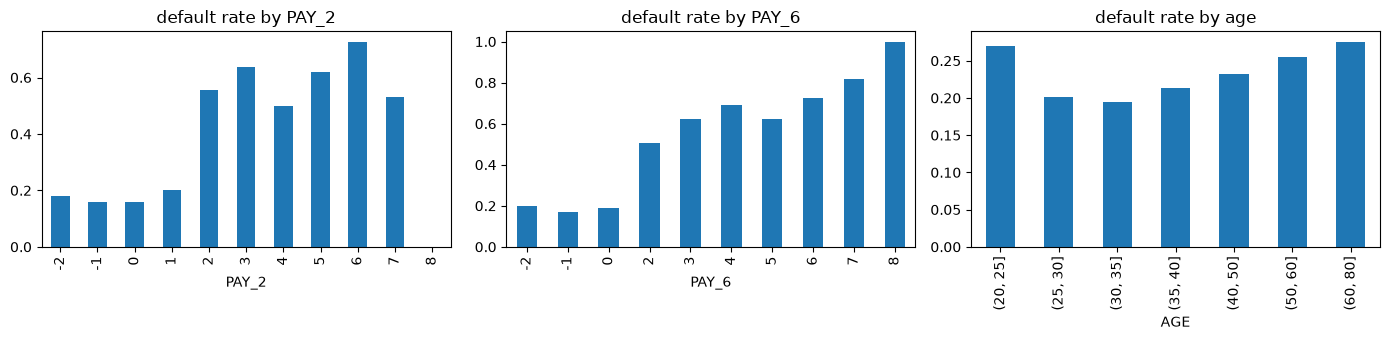

In [10]:
eda[BILLS].corr().round(2)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
eda.groupby("PAY_2")["default"].mean().plot.bar(ax=ax[0], title="default rate by PAY_2")
eda.groupby("PAY_6")["default"].mean().plot.bar(ax=ax[1], title="default rate by PAY_6")
eda.groupby(pd.cut(eda["AGE"], [20, 25, 30, 35, 40, 50, 60, 80]))["default"].mean().plot.bar(ax=ax[2], title="default rate by age")
plt.tight_layout(); plt.show()

In [11]:
for c in ["PAY_2", "PAY_6"]:
    print(c, eda[c].value_counts().sort_index().to_dict())

PAY_2 {-2: 3030, -1: 4845, 0: 12573, 1: 25, 2: 3145, 3: 254, 4: 78, 5: 21, 6: 11, 7: 17, 8: 1}
PAY_6 {-2: 3942, -1: 4576, 0: 13008, 2: 2230, 3: 149, 4: 42, 5: 8, 6: 11, 7: 33, 8: 1}


In [12]:
from features import make_prep

prep = make_prep().fit(X_train)
X_train_p = prep.transform(X_train)
X_test_p = prep.transform(X_test)
feature_names = list(prep.get_feature_names_out())
print(X_train_p.shape, X_test_p.shape)

(24000, 78) (6000, 78)
